In [64]:
import numpy as np
from cosmoTransitions.tunneling1D import SingleFieldInstanton
import matplotlib.pyplot as plt
import math
import pandas as pd
from scipy import optimize as optimize
import scipy.integrate as integrate
from scipy import interpolate, special


####Some definitions##
v2 = 246.**2 
mh=125
v=246
alpha=1/137 #fine structure constant
sinthw=np.sqrt(0.223) #sine of Weinberg angle
g1=np.sqrt(4*np.pi*alpha/(1-sinthw**2)) ## U(1)_Y gauge coupling constant
g=np.sqrt(4*np.pi*alpha)/sinthw #SU(2)_L gauge coupling constant
Mplanck=2.4*10**18 #reduced planck mass
mZ=np.sqrt(v**2/4*(g**2+g1**2))###Z boson mass

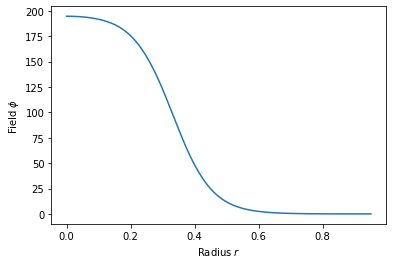

In [65]:
#Definition of the potential#
Tc = 100.
L = 0.1*Tc**4
sigma = 0.1*Tc**3
lc = 6/Tc
T0 = Tc/(1+6*sigma/(L*lc))**0.5
alpha = 1/(2/3*sigma*lc**5*Tc**2)**0.5
gamma = (L+6*sigma/lc)/(6*sigma*lc*Tc**2)
lam = 1/(3*sigma*lc**3)
Tn = 93.
def V(phi): return 0.5*gamma*(Tn**2-T0**2)*phi**2-1/3*alpha*Tn*phi**3+0.25*lam*phi**4
def dV(phi): return gamma*(Tn**2-T0**2)*phi-alpha*Tn*phi**2+lam*phi**3

#critical bubble#
xi = np.array(range(2500000))*0.0001
Vmin = np.amin(V(xi))
vt = xi[np.where(V(xi) == Vmin)[0]][0] ##find location of the global minimum
profile = SingleFieldInstanton(vt, 0.0, V, dV).findProfile(npoints=1000)
plt.plot(profile.R, profile.Phi)
plt.xlabel(r"Radius $r$")
plt.ylabel(r"Field $\phi$")
plt.show()

In [66]:
#Thermodynamical quantities#
gst = 106.75
a = gst*(math.pi**2)/90
def VT(field,temp): return 0.5*gamma*(temp**2-T0**2)*field**2-1/3*alpha*temp*field**3+0.25*lam*field**4
def dVT(field,temp): return gamma*(temp**2-T0**2)*field-alpha*temp*field**2+lam*field**3
def eps(field, temp): return 3*a*temp**4+ VT(field,temp)- temp*dVT(field,temp)
def p(field,temp): return a*temp**4-VT(field,temp)
def w(field,temp): return eps(field,temp)+p(field,temp)
def gam(v): return 1/(1-v**2)**0.5

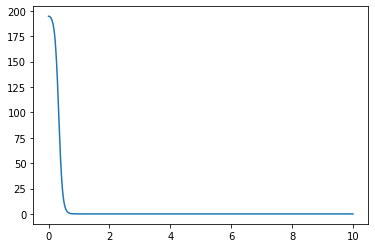

In [102]:
#initialization of the evolution#
fphi = interpolate.interp1d(profile.R, profile.Phi, fill_value=(0), bounds_error=False)
dr=0.001
dt = 0.0005
r  = np.array(range(0, int(np.floor(10/dr))))*dr
phi0 = fphi(r/1.01)
phi2 = np.zeros(r.size)
T = Tn*np.ones(r.size)
v = np.zeros(r.size)
E = gam(v)*eps(phi0,T)
Z = w(phi0,T)*gam(v)**2*v
tau = w(phi0,T)*gam(v)**2-p(phi0,T)
plt.plot(r,phi0)
plt.show()

In [ ]:
###Lattice approach, Galerkin method:

phi = phi0
phi2 = np.zeros(r.size)
N = len(tau)
for i in range(20000):#--------------------------------------------------iterate over time
    #------1 step evolution
    phi[1:-1] = 0.5*dt*phi2[1:-1] + phi[1:-1]
    phi[0] = phi[1]
    #------2nd step evolution
    phi2[1] = phi2[1] + dt*((r[1]**2+r[2]**2)/((r[0]**2+2*r[1]**2)*dr**2)*(phi[2]-phi[1])-dVT(phi[1],T[1]))
    for j in range(2, N-1):
        phi2[j] = phi2[j] + dt*((r[j+1]**2+r[j]**2)/(2*r[j]**2*dr**2)*(phi[j+1]-phi[j])-(r[j]**2+r[j-1]**2)/(2*r[j]**2*dr**2)*(phi[j]-phi[j-1])-dVT(phi[j],T[j]))
    #-------3rd step evolution
    phi[1:-1] = 0.5*dt*phi2[1:-1] + phi[1:-1]
    phi[0] = phi[1]
    #------plotting
    if(i%2000==0):
        plt.plot(r,phi,label= str(i/Tc)+"*Tc")
        plt.xlim(0,10)
        plt.xlabel("r")
        plt.title("dr = 0.001, dt = 0.0005")
        plt.ylabel("phi")
        plt.axhline(y = vt, color = 'gray', linestyle = 'dashed')
        #plt.legend()
        #plt.plot(r,tau)